# Keeping the Design: Geometry and Material Preservation in AI Interior Renders

**Goal.** AI render tools turn an interior image into a photorealistic render. Architects want the render to **keep their design**: the same walls, windows, furniture and colors. A common failure is that the model changes things it should not change.

**Question.** If I ask for one change (*"light oak wooden floor"*), how well does each method keep everything else?

**Methods compared**
1. **Canny only**: the model gets only the edge lines of the room.
2. **Canny + img2img**: the model gets the edge lines **and** the original photo.

**How I measure**
| Metric | What it tells | Better |
|---|---|---|
| SSIM | How similar the structure is (0–1) | higher |
| Edge recall | Share of the original lines that are still in the render | higher |
| Mean ΔE (CIEDE2000) | Average color change per pixel | lower |
| CLIP score gain | How much better the image matches the requested change | higher |

Setup: Stable Diffusion 1.5 + ControlNet (Canny), float16, free Colab T4 GPU, fixed seed (42) so every run is reproducible.

## 1. Setup
Install the libraries. `torchao` is removed because an old preinstalled version breaks `diffusers` on Colab.

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU
This must print `True` and `Tesla T4`. If not: *Runtime → Change runtime type → T4 GPU*.

In [2]:
import torch
print(torch.__version__)
print("GPU:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.11.0+cu130
GPU: True
Tesla T4


## 3. Upload the room images
Choose one or more interior photos. The file names are saved in `images`.

In [3]:
from google.colab import files
uploaded = files.upload()
images = list(uploaded)
print(images)

Saving open-plan.jpg to open-plan.jpg
Saving living-room.jpg to living-room.jpg
Saving room.jpg to room.jpg
['open-plan.jpg', 'living-room.jpg', 'room.jpg']


## 4. Load the models (run once)
- **ControlNet (Canny)** makes the model follow the edge lines of the room.
- **Stable Diffusion 1.5** generates the image.
- `float16` uses half the GPU memory with almost the same quality.

The img2img pipeline reuses the same models, so nothing is downloaded twice.

In [4]:
import cv2, numpy as np
from PIL import Image
from diffusers import (StableDiffusionControlNetPipeline,
                       StableDiffusionControlNetImg2ImgPipeline, ControlNetModel)

controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet, torch_dtype=torch.float16).to("cuda")

pipe_i2i = StableDiffusionControlNetImg2ImgPipeline(**pipe.components)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## 5. Settings and helper functions
One prompt and one seed for every method, so the comparison is fair.

In [5]:
prompt = "photorealistic interior render, light oak wooden floor, white walls, natural daylight"
negative = "blurry, distorted, low quality, deformed"
W, H = 768, 432   # keeps the 16:9 shape (both numbers are multiples of 8)
SEED = 42

def load_room(name):
    return Image.open(name).convert("RGB").resize((W, H))

def make_edges(room):
    edges = cv2.Canny(np.array(room), 100, 200)          # white lines on black
    return Image.fromarray(np.stack([edges] * 3, axis=-1)) # 1 channel -> 3 channels

def show_row(imgs):
    row = Image.new("RGB", (W * len(imgs), H))
    for i, im in enumerate(imgs):
        row.paste(im, (i * W, 0))
    display(row)

## 6. Method A: Canny only
The model sees only the edge lines. Shown: **original | edges | render**.

  0%|          | 0/25 [00:00<?, ?it/s]

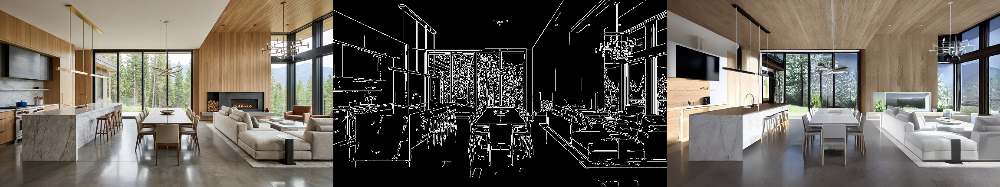

  0%|          | 0/25 [00:00<?, ?it/s]

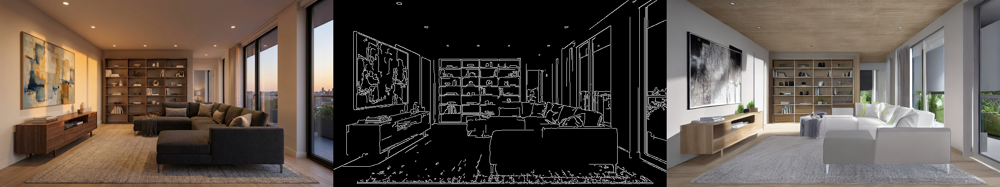

  0%|          | 0/25 [00:00<?, ?it/s]

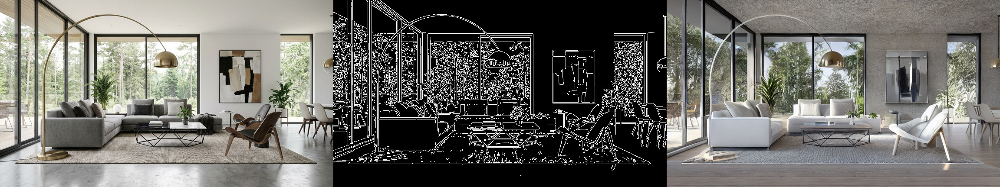

In [6]:
for name in images:
    room = load_room(name)
    edges = make_edges(room)
    result = pipe(prompt, negative_prompt=negative, image=edges,
                  width=W, height=H, num_inference_steps=25,
                  generator=torch.manual_seed(SEED)).images[0]
    result.save(f"render_{name}")
    show_row([room, edges, result])

**What I saw.** The geometry stayed (windows, kitchen island, shelves, the arc lamp). But the materials drifted: dark sofas and chairs turned white, paintings lost their colors, a fireplace became a window, and "wooden floor" was applied to the ceiling in one image.

**Why.** Edge lines carry no color information, so the model invents the colors.

## 7. Method B: Canny + img2img
The model starts from the original photo (`image=room`) and still follows the edges (`control_image=edges`).
`strength` sets how much may change: 0 = nothing, 1 = everything.
Shown: **original | Method A | Method B**.

  0%|          | 0/15 [00:00<?, ?it/s]

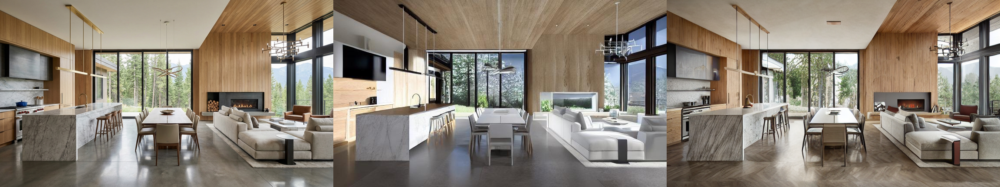

  0%|          | 0/15 [00:00<?, ?it/s]

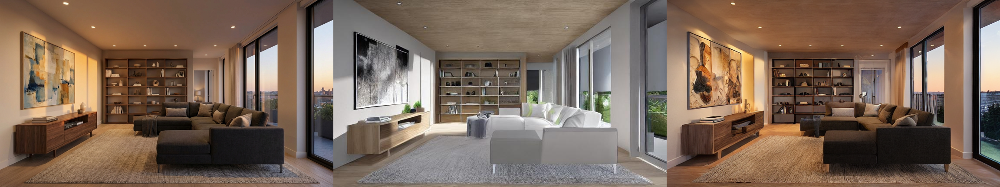

  0%|          | 0/15 [00:00<?, ?it/s]

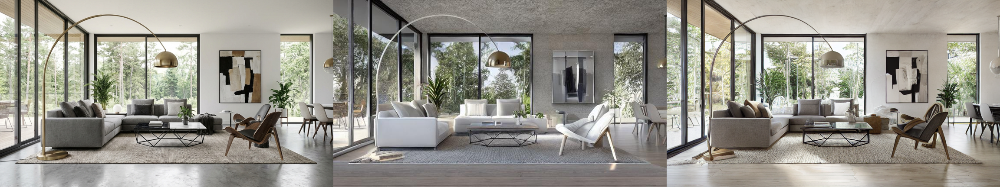

In [7]:
for name in images:
    room = load_room(name)
    edges = make_edges(room)
    result_i2i = pipe_i2i(prompt, negative_prompt=negative,
                          image=room, control_image=edges, strength=0.6,
                          num_inference_steps=25,
                          generator=torch.manual_seed(SEED)).images[0]
    result_i2i.save(f"render_i2i_{name}")
    show_row([room, Image.open(f"render_{name}"), result_i2i])

**What I saw.** Sofa and chair colors, the fireplace and the warm light are kept, and the concrete floor became wood. Remaining problems: one painting changed its content, and "natural daylight" was not applied, because img2img stays close to the original.

## 8. Measure Method A vs Method B
- **SSIM**: structural similarity of the grayscale images.
- **Edge recall**: share of the original edges found again in the render (a 5×5 dilation allows small shifts).
- **Mean ΔE**: average CIEDE2000 color difference in CIELAB space. ΔE < 2 is hard to see, ΔE > 10 is a clear change.

In [9]:
from skimage.metrics import structural_similarity as ssim
from skimage.color import rgb2lab, deltaE_ciede2000
import pandas as pd

def edge_recall(orig, render):
    e_orig = cv2.Canny(orig, 100, 200) > 0
    e_rend = cv2.Canny(render, 100, 200) > 0
    e_rend = cv2.dilate(e_rend.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (e_orig & e_rend).sum() / e_orig.sum()

def mean_delta_e(orig, render):
    return deltaE_ciede2000(rgb2lab(orig), rgb2lab(render)).mean()

rows = []
for name in images:
    orig = np.array(load_room(name))
    for method, file in [("A: Canny only", f"render_{name}"),
                         ("B: Canny + img2img", f"render_i2i_{name}")]:
        rend = np.array(Image.open(file).convert("RGB").resize((W, H)))
        rows.append({
            "image": name, "method": method,
            "SSIM ↑": ssim(cv2.cvtColor(orig, cv2.COLOR_RGB2GRAY), cv2.cvtColor(rend, cv2.COLOR_RGB2GRAY)),
            "Edge recall ↑": edge_recall(orig, rend),
            "Mean ΔE ↓": mean_delta_e(orig, rend),
        })

df = pd.DataFrame(rows)
display(df.round(3))
display(df.groupby("method").mean(numeric_only=True).round(3))

,image,method,SSIM ↑,Edge recall ↑,Mean ΔE ↓
0,open-plan.jpg,A: Canny only,0.368,0.850,20.246
1,open-plan.jpg,B: Canny + img2img,0.535,0.926,9.367
2,living-room.jpg,A: Canny only,0.414,0.896,22.320
3,living-room.jpg,B: Canny + img2img,0.632,0.921,7.787
4,room.jpg,A: Canny only,0.280,0.925,23.057
5,room.jpg,B: Canny + img2img,0.533,0.955,9.511


,SSIM ↑,Edge recall ↑,Mean ΔE ↓
method,,,
A: Canny only,0.354,0.890,21.874
B: Canny + img2img,0.567,0.934,8.888


**Result (3 images, seed 42).** Method B was better on every metric and on every image:

| Method | SSIM ↑ | Edge recall ↑ | Mean ΔE ↓ |
|---|---|---|---|
| A: Canny only | 0.354 | 0.890 | 21.9 |
| B: Canny + img2img | **0.567** | **0.934** | **8.9** |

Adding the original photo cut the color change by about 59% and kept 93% of the original edges.

**Limits.** Only 3 images and one seed. ΔE also counts the floor, which I changed on purpose.

## 9. Experiment 2: the strength trade-off
Method B has a cost: the more it keeps the original, the weaker the prompt. I test `strength` from 0.4 to 0.8 and measure two things:
- **Mean ΔE** (lower = colors kept better)
- **CLIP score gain**: how much more the render matches *"a room with a light oak wooden floor"* than the original photo does. CLIP is a model that scores how well an image and a text match.

In [10]:
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda")
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
target_text = "a room with a light oak wooden floor"

def clip_score(img, text=target_text):
    inputs = clip_proc(text=[text], images=img, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        out = clip(**inputs)
    return float((out.image_embeds @ out.text_embeds.T).item() * 100)  # cosine similarity x 100

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

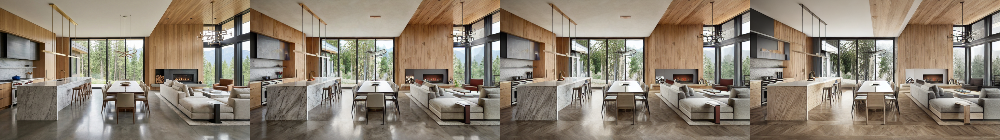

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

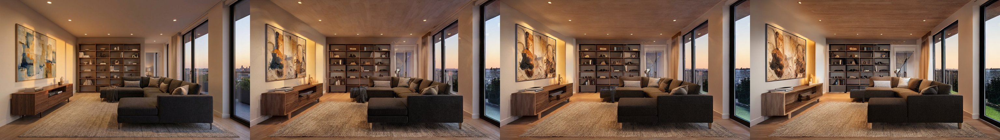

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

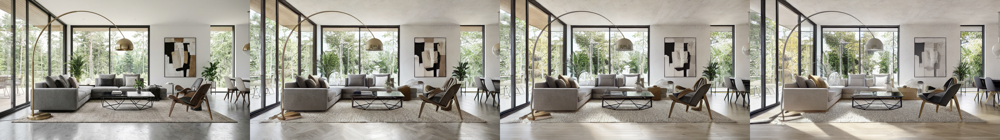

,Mean ΔE ↓,CLIP gain ↑
strength,,
0.4,7.16,1.08
0.5,7.78,1.37
0.6,8.94,1.52
0.7,10.06,2.45
0.8,12.18,1.66


In [11]:
strengths = [0.4, 0.5, 0.6, 0.7, 0.8]
rows = []
for name in images:
    room = load_room(name)
    edges = make_edges(room)
    base_clip = clip_score(room)
    renders = []
    for s in strengths:
        out = pipe_i2i(prompt, negative_prompt=negative,
                       image=room, control_image=edges, strength=s,
                       num_inference_steps=25,
                       generator=torch.manual_seed(SEED)).images[0]
        out.save(f"render_s{s}_{name}")
        renders.append(out)
        rows.append({"image": name, "strength": s,
                     "Mean ΔE ↓": mean_delta_e(np.array(room), np.array(out)),
                     "CLIP gain ↑": clip_score(out) - base_clip})
    show_row([room] + renders[::2])   # original | 0.4 | 0.6 | 0.8

sweep = pd.DataFrame(rows)
summary = sweep.groupby("strength").mean(numeric_only=True).round(2)
display(summary)

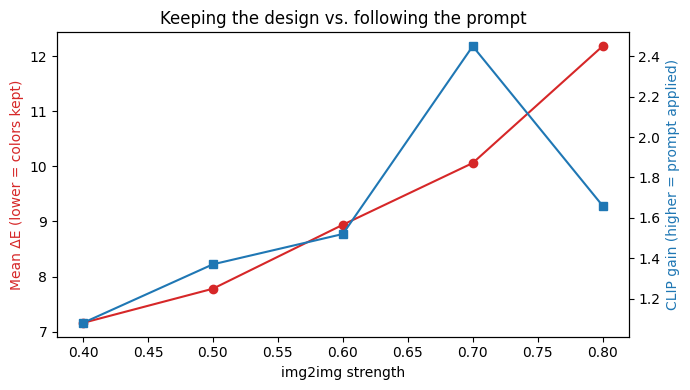

In [12]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(summary.index, summary["Mean ΔE ↓"], "o-", color="tab:red", label="Mean ΔE (color change)")
ax1.set_xlabel("img2img strength")
ax1.set_ylabel("Mean ΔE (lower = colors kept)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(summary.index, summary["CLIP gain ↑"], "s-", color="tab:blue", label="CLIP gain (prompt match)")
ax2.set_ylabel("CLIP gain (higher = prompt applied)", color="tab:blue")
plt.title("Keeping the design vs. following the prompt")
fig.tight_layout()
plt.savefig("strength_tradeoff.png", dpi=150)
plt.show()

**Findings**
- As strength goes up, colors drift more: mean ΔE rises steadily from 7.2 (0.4) to 12.2 (0.8).
- The prompt is applied better up to 0.7 (CLIP gain 1.1 → 2.5), but at 0.8 it drops to 1.7, because the model starts changing things it should not change (the marble island turned into wood, paintings faded).
- The best balance for this task is around strength 0.6–0.7.
- Paintings are the weakest point: their content changed even at 0.4.

*Limits: 3 images and one seed, and one room already had a wooden floor. The CLIP peak at 0.7 needs more images and seeds to confirm.*

## 10. What went wrong and what I learned
- *Problem:* with edges only, colors and materials drifted (ΔE ≈ 22).
- *Cause:* Canny edges carry no color information.
- *Fix:* add the original photo as img2img input → ΔE ≈ 9, edge recall 93%.
- *New problem:* the prompt becomes weaker (daylight not applied, a painting changed).
- *Measured the trade-off:* higher strength applies the prompt better but changes more colors. The best balance was around strength 0.6–0.7; at 0.8 the model started changing things it should not (the marble island turned into wood).
- *Next:* mask the floor (inpainting) so only the requested area can change, and measure ΔE only outside the mask.

## 11. Download the results

In [13]:
!zip -q results.zip render_*.jpg strength_tradeoff.png
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import os
os.makedirs("results", exist_ok=True)

for n, name in enumerate(images, start=1):
    room = load_room(name)
    open_ = lambda f: Image.open(f).convert("RGB").resize((W, H))

    # original | Method A | Method B
    imgs = [room, open_(f"render_{name}"), open_(f"render_i2i_{name}")]
    row = Image.new("RGB", (W * 3, H))
    for i, im in enumerate(imgs):
        row.paste(im, (i * W, 0))
    row.save(f"results/method_comparison_{n}.jpg", quality=90)

    # original | strength 0.4 | 0.6 | 0.8
    imgs = [room] + [open_(f"render_s{s}_{name}") for s in [0.4, 0.6, 0.8]]
    row = Image.new("RGB", (W * 4, H))
    for i, im in enumerate(imgs):
        row.paste(im, (i * W, 0))
    row.save(f"results/strength_sweep_{n}.jpg", quality=90)

!cp strength_tradeoff.png results/
!zip -q -r results_clean.zip results
files.download("results_clean.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>